Original Dataset:
    Age  Income
0    20      20
1    22      22
2    21      19
3    23      25
4    25      24
5    45      70
6    46      75
7    44      68
8    48      80
9    50      78
10   30      40
11   32      42
12   31      38
13   29      45
14   33      43

Dataset after K-Means Clustering:
    Age  Income  Cluster
0    20      20        1
1    22      22        1
2    21      19        1
3    23      25        1
4    25      24        1
5    45      70        0
6    46      75        0
7    44      68        0
8    48      80        0
9    50      78        0
10   30      40        2
11   32      42        2
12   31      38        2
13   29      45        2
14   33      43        2

Cluster Centers:
[[46.6 74.2]
 [22.2 22. ]
 [31.  41.6]]


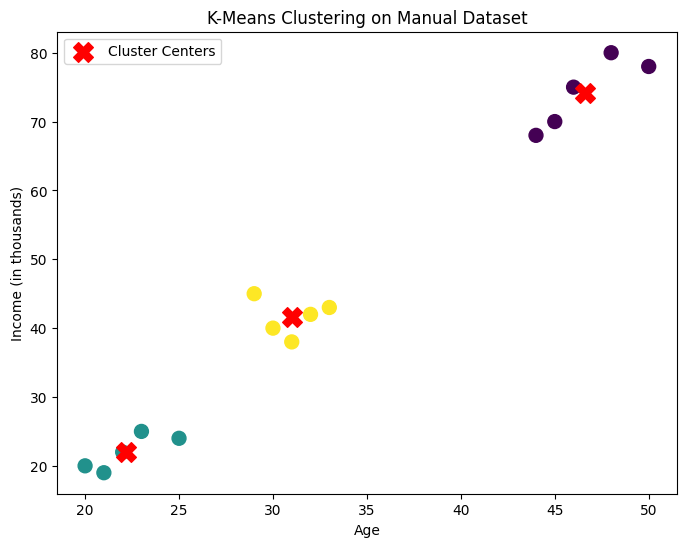

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Create a manual dataset
data = {
    "Age": [20, 22, 21, 23, 25, 45, 46, 44, 48, 50, 30, 32, 31, 29, 33],
    "Income": [20, 22, 19, 25, 24, 70, 75, 68, 80, 78, 40, 42, 38, 45, 43]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 2. Select features for clustering
X = df[["Age", "Income"]]

# 3. Create K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# 4. Train the model and assign clusters
df["Cluster"] = kmeans.fit_predict(X)

# 5. Display the clustered dataset
print("\nDataset after K-Means Clustering:")
print(df)

# 6. Display cluster centers
print("\nCluster Centers:")
print(kmeans.cluster_centers_)

# 7. Visualize the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Age"],
    df["Income"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

# Plot cluster centers
centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Cluster Centers"
)

plt.xlabel("Age")
plt.ylabel("Income (in thousands)")
plt.title("K-Means Clustering on Manual Dataset")
plt.legend()
plt.show()


Dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Clustered Dataset:
    sepal_length  sepal_width  petal_length  petal_width species  Cluster
0            5.1          3.5           1.4          0.2  setosa        1
1            4.9          3.0           1.4          0.2  setosa        1
2            4.7          3.2           1.3          0.2  setosa        1
3            4.6          3.1           1.5          0.2  setosa        1
4            5.0          3.6           1.4          0.2  setosa        1
5            5.4          3.9           1.7          0.4  setosa        1
6            4.6          3.4           1.4          0.3  setosa     

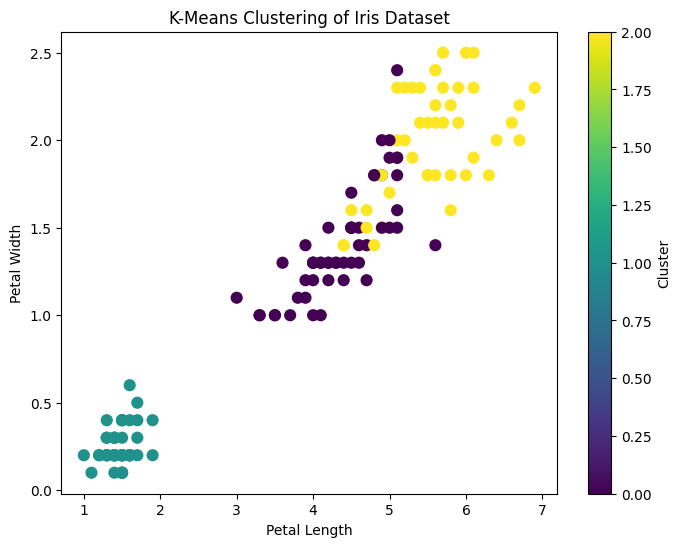

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Read dataset directly from the internet
url = "https://raw.githubusercontent.com/uiuc-cse/data-fa14/gh-pages/data/iris.csv"

df = pd.read_csv(url)

print("Dataset:")
print(df.head())

# 2. Select numerical features
X = df[["sepal_length", "sepal_width",
        "petal_length", "petal_width"]]

# 3. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Display results
print("\nClustered Dataset:")
print(df.head(20))

# 6. Display number of points in each cluster
print("\nNumber of data points in each cluster:")
print(df["Cluster"].value_counts())

# 7. Display cluster centers
print("\nCluster Centers:")
print(kmeans.cluster_centers_)

# 8. Visualize clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    df["petal_length"],
    df["petal_width"],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clustering of Iris Dataset")
plt.colorbar(label="Cluster")

plt.show()
